# Protein Analysis

This notebook visualises the persistent homology results computed by
`applications/analyse_proteins.py` on three proteins from the RCSB
Protein Data Bank:

* **1AKI** - Lysozyme (129 residues, single-domain enzyme)
* **1EMA** - Green Fluorescent Protein (221 residues, beta-barrel)
* **1A3N** - Hemoglobin (572 residues, tetramer)

The notebook is read-only with respect to computation: it loads the
`.npy` diagrams and the `.csv` summaries produced by the script and
turns them into figures and tables. Re-running `analyse_proteins.py`
is the way to refresh the underlying data.

## Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers 3d projection)

# Find the repo root so we can import the package and locate data.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from persistent_homology.plotting import plot_persistence_diagram

COORDS_DIR = ROOT / "data" / "proteins" / "ca_coords"
RESULTS_DIR = ROOT / "data" / "proteins" / "results"
FIGURES_DIR = ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

PROTEINS = [
    {"id": "1AKI", "name": "Lysozyme",                  "colour": "#1565C0"},
    {"id": "1EMA", "name": "Green Fluorescent Protein", "colour": "#2E7D32"},
    {"id": "1A3N", "name": "Hemoglobin",                "colour": "#C62828"},
]

# Persistence threshold below which features are treated as backbone noise.
PERSISTENCE_THRESHOLD = 2.0   # angstroms
FILTRATION_THRESHOLD  = 12.0  # angstroms

In [2]:
def load_coords(pdb_id):
    """Load Calpha coordinates for one protein."""
    return np.load(COORDS_DIR / f"{pdb_id}_ca.npy")

def load_diagrams(pdb_id):
    """Return the three persistence diagrams (H0, H1, H2) for one protein."""
    return [np.load(RESULTS_DIR / f"{pdb_id}_dgm_H{d}.npy")
            for d in range(3)]

def diagram_to_dict(diagrams):
    """Convert a list of (n, 2) arrays to the dict format expected
    by plot_persistence_diagram."""
    return {d: [tuple(row) for row in dgm] for d, dgm in enumerate(diagrams)}

## 1. Raw data: $C_\alpha$ point clouds

We start by looking at the input data. Each protein is reduced to its
$C_\alpha$ atoms (one per residue), giving a point cloud in
$\mathbb{R}^3$ whose topology is what persistent homology will probe.

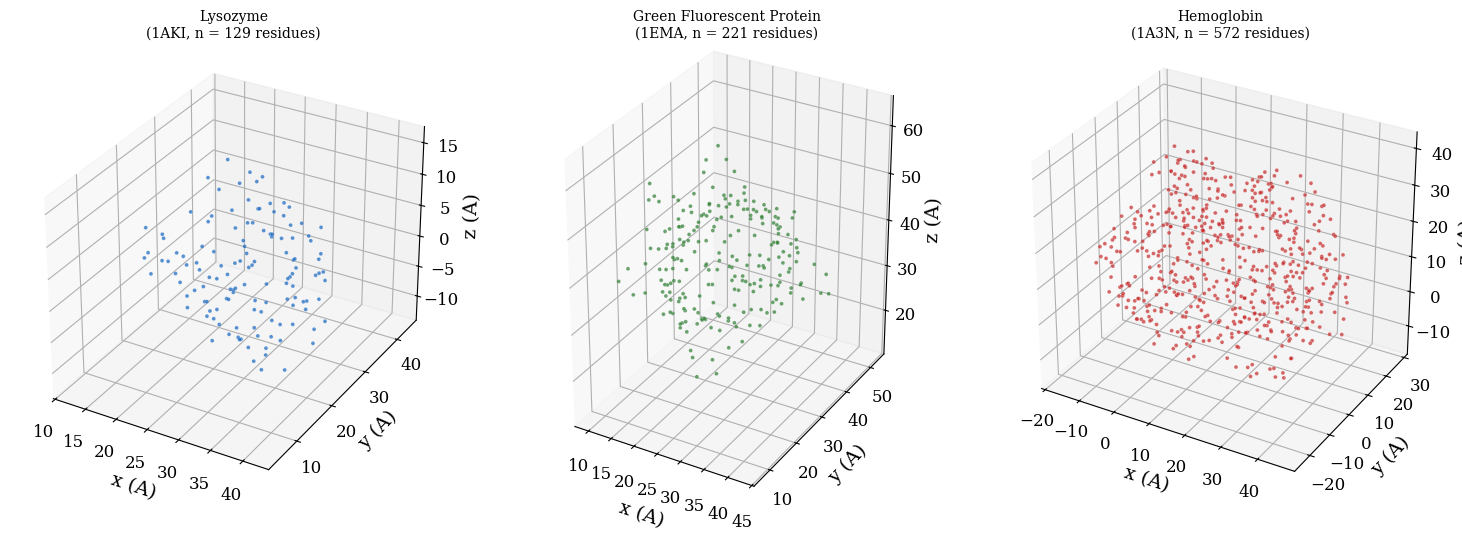

In [3]:
fig = plt.figure(figsize=(15, 5))

for i, protein in enumerate(PROTEINS):
    coords = load_coords(protein["id"])
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")
    ax.scatter(coords[:, 0], coords[:, 1], coords[:, 2],
               c=protein["colour"], s=8, alpha=0.7,
               edgecolors="white", linewidths=0.2)
    ax.set_title(f"{protein['name']}\n({protein['id']}, n = {len(coords)} residues)",
                 fontsize=10)
    ax.set_xlabel("x (A)")
    ax.set_ylabel("y (A)")
    ax.set_zlabel("z (A)")
    # Equal aspect ratio so the protein shapes are not distorted.
    extents = coords.max(axis=0) - coords.min(axis=0)
    ax.set_box_aspect(extents / extents.max())

plt.tight_layout()
plt.savefig(FIGURES_DIR / "protein_pointclouds.png", dpi=150, bbox_inches="tight")
plt.show()

The three proteins display strikingly different spatial organisations.
Lysozyme is roughly globular, GFP is elongated along the barrel axis,
and hemoglobin shows four distinct lobes corresponding to the four
subunits of the tetramer.

## 2. Coordinate summary

Basic geometric statistics of each point cloud.

In [4]:
rows = []
for protein in PROTEINS:
    coords = load_coords(protein["id"])
    extent = coords.max(axis=0) - coords.min(axis=0)
    rows.append({
        "Protein": f"{protein['name']} ({protein['id']})",
        "n residues": coords.shape[0],
        "Bounding box (A)": f"{extent[0]:.0f} x {extent[1]:.0f} x {extent[2]:.0f}",
        "Diameter (A)": f"{np.linalg.norm(extent):.0f}",
    })

summary = pd.DataFrame(rows)
summary

,Protein,n residues,Bounding box (A),Diameter (A)
0,Lysozyme (1AKI),129,30 x 38 x 28,56
1,Green Fluorescent Protein (1EMA),221,34 x 45 x 49,75
2,Hemoglobin (1A3N),572,62 x 52 x 55,98


## 3. Persistence diagrams

For each protein we plot the full persistence diagram up to $H_2$, with
$H_0$, $H_1$ and $H_2$ overlaid on the same axes. Points far from the
diagonal correspond to long-lived (persistent) topological features.

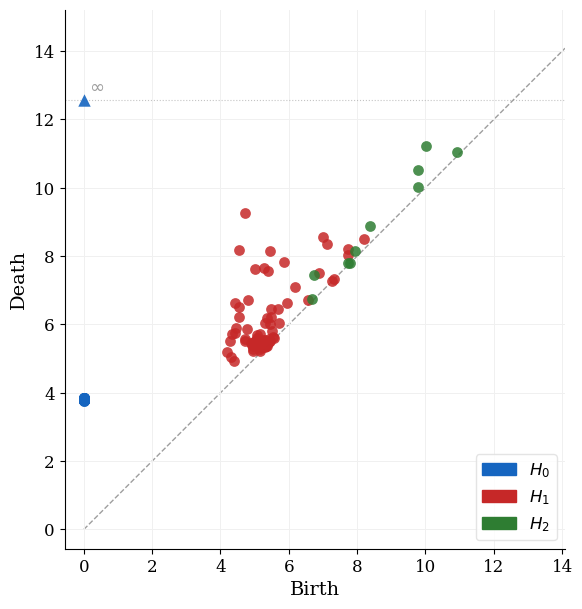

Saved /home/roy/AIMS_courses/master_thesis/persistent-homology/figures/protein_diagram_1AKI.png


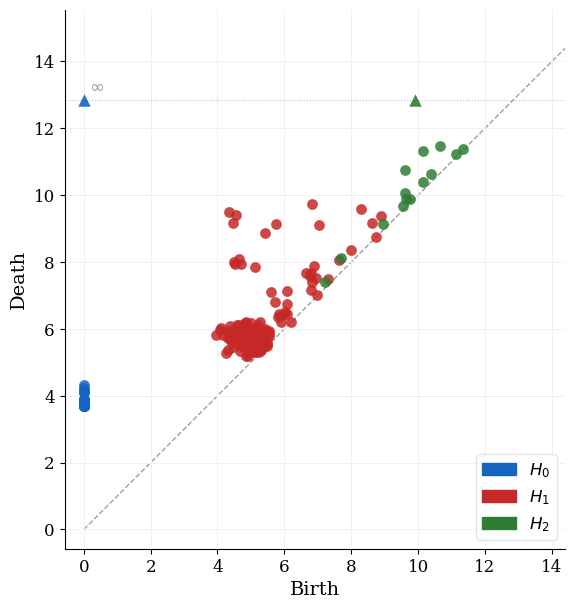

Saved /home/roy/AIMS_courses/master_thesis/persistent-homology/figures/protein_diagram_1EMA.png


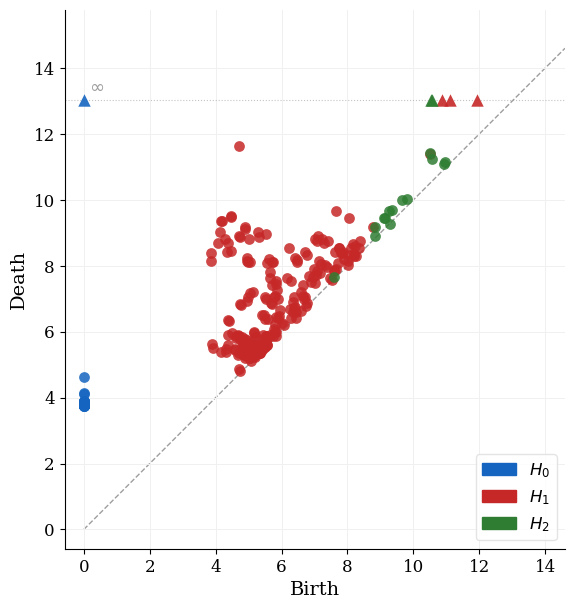

Saved /home/roy/AIMS_courses/master_thesis/persistent-homology/figures/protein_diagram_1A3N.png


In [10]:
for protein in PROTEINS:
    diagrams = load_diagrams(protein["id"])
    diag_dict = diagram_to_dict(diagrams)

    fig, ax = plt.subplots(figsize=(7, 7))
    plot_persistence_diagram(
        diag_dict, max_dim=2,
        title="",  # f"{protein['name']} ({protein['id']})",
        ax=ax,
    )
    out = FIGURES_DIR / f"protein_diagram_{protein['id']}.png"
    plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved {out}")

## 4. Side-by-side comparison

To make the progression of topological complexity visible at a glance,
we plot the three diagrams side by side.

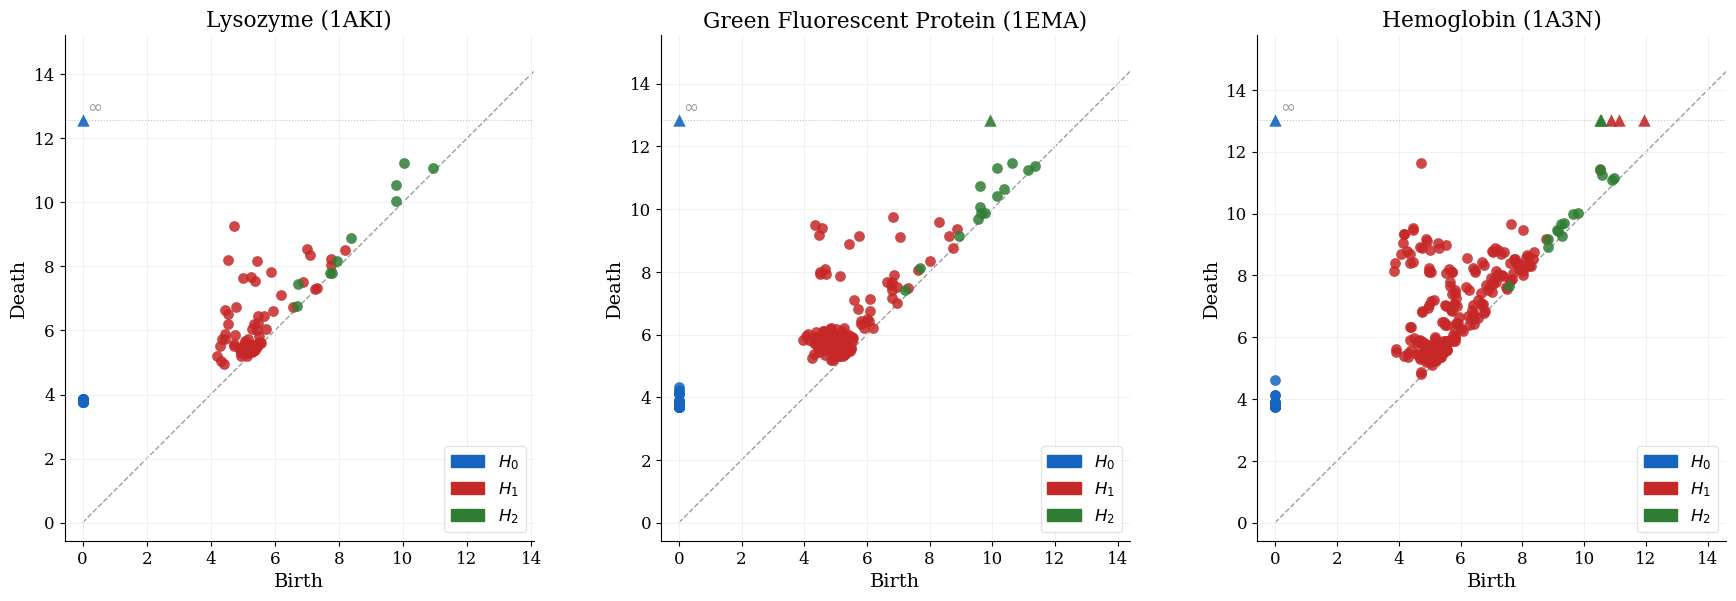

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, protein in zip(axes, PROTEINS):
    diag_dict = diagram_to_dict(load_diagrams(protein["id"]))
    plot_persistence_diagram(
        diag_dict, max_dim=2,
        title=f"{protein['name']} ({protein['id']})",
        ax=ax,
    )
plt.tight_layout()
plt.savefig(FIGURES_DIR / "protein_diagrams_comparison.png",
            dpi=150, bbox_inches="tight")
plt.show()

The three diagrams illustrate the increasing topological complexity:
from a few loops in lysozyme, to richer barrel-loop structure in GFP,
to the elaborate inter-subunit topology of hemoglobin.

## 5. Betti counts and persistent features

Counts of persistent features (persistence > 2 A) and essential
features (those that survive the entire filtration), as computed by
`analyse_proteins.py`.

In [7]:
betti = pd.read_csv(RESULTS_DIR / "betti_counts.csv")
# Reshape to wide format: one row per protein, columns for each Hk count.
pivot_persistent = betti.pivot(index="protein", columns="dimension",
                                values="persistent").rename(
    columns={0: "H0 persistent", 1: "H1 persistent", 2: "H2 persistent"})
pivot_essential = betti.pivot(index="protein", columns="dimension",
                              values="essential").rename(
    columns={0: "H0 essential", 1: "H1 essential", 2: "H2 essential"})
table = pd.concat([pivot_persistent, pivot_essential], axis=1)
table = table[["H0 persistent", "H1 persistent", "H2 persistent",
               "H0 essential", "H1 essential", "H2 essential"]]
table

dimension,H0 persistent,H1 persistent,H2 persistent,H0 essential,H1 essential,H2 essential
protein,,,,,,
1A3N,571,37,0,1,3,2
1AKI,128,7,0,1,0,0
1EMA,220,12,0,1,0,1


The H1 persistent counts (loops) and H2 persistent counts (voids)
are the topologically informative quantities for the chapter. The
pattern matches the structural progression of the three proteins.

## 6. Lysozyme: comparison of five implementations

`benchmark_lysozyme.py` runs the three Python reductions plus Ripser
and GUDHI on lysozyme. This is the real-data counterpart of the
synthetic benchmarks of Chapter 5: do our implementations behave the
same way on actual biological input?

In [9]:
bench_path = RESULTS_DIR / "lysozyme_benchmark.csv"
if bench_path.exists():
    bench = pd.read_csv(bench_path)
    bench = bench.assign(
        time_s=bench["time_s"].round(3),
        speedup_vs_ripser=bench["speedup_vs_ripser"].round(2),
    )
    display(bench)
else:
    print(f"{bench_path.name} not found. "
          "Run applications/benchmark_lysozyme.py first.")

,implementation,time_s,b0,b1,b2,speedup_vs_ripser
0,Our standard,12.001,129,7,0,1271.42
1,Our clearing,11.712,129,7,0,1240.89
2,Our cohomology,11.449,129,7,0,1213.03
3,Ripser,0.009,129,7,0,1.00
4,GUDHI,0.020,129,7,0,2.16


Where the Betti counts agree across implementations, the differences
are purely in computation time. The relative ordering matches the
Chapter 5 conclusions on dense synthetic data.